In [1]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        tf.config.experimental.set_memory_growth(gpus[0], True)
        tf.config.set_visible_devices(gpus[0], 'GPU')
        print("Using GPU:", gpus[0])
    except RuntimeError as e:
        print("Error setting up GPU:", e)
else:
    print("No GPU found, using CPU instead.")


2024-12-23 21:29:43.037167: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-12-23 21:29:43.226473: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-12-23 21:29:46.865678: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /usr/local/cuda/lib64:/usr/local/cuda/lib:/usr/local/lib/x86_64-linux-gnu:/usr/local/nvidia/lib:/usr/local/nvidia/lib64:/usr/local/nvidia/lib:/usr/local/nvidia/lib64
2024-12-23 21:29:46.865836: W tensorfl

Using GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


2024-12-23 21:29:50.371682: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-12-23 21:29:50.389581: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2024-12-23 21:29:50.392878: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero


In [2]:
import pandas as pd
datatrain =pd.read_csv("testdata.csv")
datatrain         

,ImgName,GroundTruth,smallLexi,mediumLexi
0,test/1002_1.png,PRIVATE,"['PRIVATE', '136', '17', '3SIDED', '55496002',...","['PRIVATE', '008', '02', '020', '05', '0726813..."
1,test/1002_2.png,PARKING,"['PARKING', '112009', '220', '227', '22A', '24...","['PARKING', '005216', '008', '02', '020', '072..."
2,test/1009_1.png,SALUTES,"['SALUTES', '167', 'AFFECTS', 'ANGELINA', 'BE'...","['SALUTES', '005216', '008', '01922', '02', '0..."
3,test/100_1.png,DOLCE,"['DOLCE', '1200PM', '2003', '40', '604', '6279...","['DOLCE', '005216', '01922', '02', '05', '0726..."
4,test/100_2.png,GABBANA,"['GABBANA', '08', '10DIGIT', '12', '19', '2010...","['GABBANA', '005216', '01922', '02', '05', '07..."
...,...,...,...,...
2995,test/997_9.png,DAY,"['DAY', '11', '31', '4567', 'AFFECTS', 'AFTER'...","['DAY', '005216', '008', '01922', '02', '05', ..."
2996,test/999_1.png,HOW,"['HOW', '1212', '26', '3602', '50TH', '53327',...","['HOW', '008', '01922', '02', '020', '05', '08..."
2997,test/999_6.png,AT,"['AT', '05', '100', '215', '222', '43', '604',...","['AT', '005216', '008', '01922', '02', '072681..."
2998,test/999_7.png,70,"['70', '123456', '2', '2419', '25', '46143994'...","['70', '005216', '01922', '02', '05', '08', '0..."


In [3]:
datatest=pd.read_csv("traindata.csv")
datatest  

,ImgName,GroundTruth,smallLexi,mediumLexi
0,train/1009_2.png,YOU,"['YOU', '1200', '1300', '135', '149', '324', '...","['YOU', '0', '000', '010050', '0123', '019901'..."
1,train/1017_1.png,RESCUE,"['RESCUE', '16', '208', '226', '300', '629', '...","['RESCUE', '0', '0123', '01234', '01922', '06'..."
2,train/1017_2.png,MISSION,"['MISSION', '0', '10234', '123', '1380', '2008...","['MISSION', '0', '000', '01234', '01922', '019..."
3,train/1021_1.png,HOME,"['HOME', '010050', '143KM', '2008', '208', '25...","['HOME', '0', '000', '010050', '01234', '01990..."
4,train/1023_1.png,BORDER,"['BORDER', '12', '143KM', '17', '2003', '2009'...","['BORDER', '0', '000', '010050', '0123', '0123..."
...,...,...,...,...
1995,train/997_7.png,FOR,"['FOR', '12345', '1300', '162', '165', '183', ...","['FOR', '0', '000', '0123', '01234', '01922', ..."
1996,train/999_2.png,TO,"['TO', '1', '12345', '124', '183', '22', '26',...","['TO', '0', '000', '010050', '0123', '01922', ..."
1997,train/999_3.png,WRITE,"['WRITE', '1200', '12TH', '212', '324', '4377'...","['WRITE', '0', '010050', '0123', '01234', '019..."
1998,train/999_4.png,GREAT,"['GREAT', '019901', '112009', '1472', '16', '2...","['GREAT', '000', '010050', '0123', '01234', '0..."


In [4]:
datatrain['images']="IIIT5K-Word_V3.0/IIIT5K/"+datatrain['ImgName']
datatrain['label']=datatrain['GroundTruth'].str.lower()
datatrain

,ImgName,GroundTruth,smallLexi,mediumLexi,images,label
0,test/1002_1.png,PRIVATE,"['PRIVATE', '136', '17', '3SIDED', '55496002',...","['PRIVATE', '008', '02', '020', '05', '0726813...",IIIT5K-Word_V3.0/IIIT5K/test/1002_1.png,private
1,test/1002_2.png,PARKING,"['PARKING', '112009', '220', '227', '22A', '24...","['PARKING', '005216', '008', '02', '020', '072...",IIIT5K-Word_V3.0/IIIT5K/test/1002_2.png,parking
2,test/1009_1.png,SALUTES,"['SALUTES', '167', 'AFFECTS', 'ANGELINA', 'BE'...","['SALUTES', '005216', '008', '01922', '02', '0...",IIIT5K-Word_V3.0/IIIT5K/test/1009_1.png,salutes
3,test/100_1.png,DOLCE,"['DOLCE', '1200PM', '2003', '40', '604', '6279...","['DOLCE', '005216', '01922', '02', '05', '0726...",IIIT5K-Word_V3.0/IIIT5K/test/100_1.png,dolce
4,test/100_2.png,GABBANA,"['GABBANA', '08', '10DIGIT', '12', '19', '2010...","['GABBANA', '005216', '01922', '02', '05', '07...",IIIT5K-Word_V3.0/IIIT5K/test/100_2.png,gabbana
...,...,...,...,...,...,...
2995,test/997_9.png,DAY,"['DAY', '11', '31', '4567', 'AFFECTS', 'AFTER'...","['DAY', '005216', '008', '01922', '02', '05', ...",IIIT5K-Word_V3.0/IIIT5K/test/997_9.png,day
2996,test/999_1.png,HOW,"['HOW', '1212', '26', '3602', '50TH', '53327',...","['HOW', '008', '01922', '02', '020', '05', '08...",IIIT5K-Word_V3.0/IIIT5K/test/999_1.png,how
2997,test/999_6.png,AT,"['AT', '05', '100', '215', '222', '43', '604',...","['AT', '005216', '008', '01922', '02', '072681...",IIIT5K-Word_V3.0/IIIT5K/test/999_6.png,at
2998,test/999_7.png,70,"['70', '123456', '2', '2419', '25', '46143994'...","['70', '005216', '01922', '02', '05', '08', '0...",IIIT5K-Word_V3.0/IIIT5K/test/999_7.png,70


In [5]:
train_labels=datatrain['label'].tolist()
train_labels[0:2]

['private', 'parking']

In [6]:
train_images=datatrain['images'].tolist()
train_images[0:2]

['IIIT5K-Word_V3.0/IIIT5K/test/1002_1.png',
 'IIIT5K-Word_V3.0/IIIT5K/test/1002_2.png']

In [7]:
datatest['images']="IIIT5K-Word_V3.0/IIIT5K/"+datatest['ImgName']
datatest['label']=datatest['GroundTruth'].str.lower()
datatest

,ImgName,GroundTruth,smallLexi,mediumLexi,images,label
0,train/1009_2.png,YOU,"['YOU', '1200', '1300', '135', '149', '324', '...","['YOU', '0', '000', '010050', '0123', '019901'...",IIIT5K-Word_V3.0/IIIT5K/train/1009_2.png,you
1,train/1017_1.png,RESCUE,"['RESCUE', '16', '208', '226', '300', '629', '...","['RESCUE', '0', '0123', '01234', '01922', '06'...",IIIT5K-Word_V3.0/IIIT5K/train/1017_1.png,rescue
2,train/1017_2.png,MISSION,"['MISSION', '0', '10234', '123', '1380', '2008...","['MISSION', '0', '000', '01234', '01922', '019...",IIIT5K-Word_V3.0/IIIT5K/train/1017_2.png,mission
3,train/1021_1.png,HOME,"['HOME', '010050', '143KM', '2008', '208', '25...","['HOME', '0', '000', '010050', '01234', '01990...",IIIT5K-Word_V3.0/IIIT5K/train/1021_1.png,home
4,train/1023_1.png,BORDER,"['BORDER', '12', '143KM', '17', '2003', '2009'...","['BORDER', '0', '000', '010050', '0123', '0123...",IIIT5K-Word_V3.0/IIIT5K/train/1023_1.png,border
...,...,...,...,...,...,...
1995,train/997_7.png,FOR,"['FOR', '12345', '1300', '162', '165', '183', ...","['FOR', '0', '000', '0123', '01234', '01922', ...",IIIT5K-Word_V3.0/IIIT5K/train/997_7.png,for
1996,train/999_2.png,TO,"['TO', '1', '12345', '124', '183', '22', '26',...","['TO', '0', '000', '010050', '0123', '01922', ...",IIIT5K-Word_V3.0/IIIT5K/train/999_2.png,to
1997,train/999_3.png,WRITE,"['WRITE', '1200', '12TH', '212', '324', '4377'...","['WRITE', '0', '010050', '0123', '01234', '019...",IIIT5K-Word_V3.0/IIIT5K/train/999_3.png,write
1998,train/999_4.png,GREAT,"['GREAT', '019901', '112009', '1472', '16', '2...","['GREAT', '000', '010050', '0123', '01234', '0...",IIIT5K-Word_V3.0/IIIT5K/train/999_4.png,great


In [8]:
test_labels=datatest['label'].tolist()
test_labels[0:2]

['you', 'rescue']

In [9]:
test_images=datatest['images'].tolist()
test_images[0:2]

['IIIT5K-Word_V3.0/IIIT5K/train/1009_2.png',
 'IIIT5K-Word_V3.0/IIIT5K/train/1017_1.png']

In [10]:
train_characters = set(char for label in train_labels for char in label)
train_max_length = max([len(label) for label in train_labels])

print("Number of unique characters: ", len(train_characters))
print("Characters present: ", train_characters)
print("Maximum length of a word", train_max_length)

Number of unique characters:  36
Characters present:  {'k', '5', 'y', 'h', '3', '2', 'q', 'j', 'b', 'o', 'x', 'n', 'p', 'z', 'm', '0', 'd', '9', 'a', 'v', 'u', 'r', '6', 'l', '4', 'e', 'w', 's', 'c', '1', 't', 'f', 'g', '8', '7', 'i'}
Maximum length of a word 22


In [11]:
test_characters = set(char for label in test_labels for char in label)
test_max_length = max([len(label) for label in test_labels])

print("Number of unique characters: ", len(test_characters))
print("Characters present: ", test_characters)
print("Maximum length of a word", test_max_length)

Number of unique characters:  36
Characters present:  {'k', '5', 'y', 'h', '3', '2', 'q', 'j', 'b', 'o', 'x', 'n', 'p', 'z', 'm', '0', 'd', '9', 'a', 'v', 'u', 'r', '6', 'l', '4', 'e', 'w', 's', 'c', '1', 't', 'f', 'g', '8', '7', 'i'}
Maximum length of a word 22


In [12]:
import tensorflow as tf
import numpy as np

In [13]:
!pip install opencv-python-headless

  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (49.9 MB)


In [100]:
import os
import fnmatch
import cv2
import numpy as np
import string
import time

from tensorflow.keras.utils import pad_sequences
from keras.layers import Dense, LSTM, Reshape, BatchNormalization, Input, Conv2D, MaxPool2D, Lambda, Bidirectional,Dropout
from keras.models import Model
from keras.activations import relu, sigmoid, softmax
import keras.backend as K
from keras.utils import to_categorical
from keras.callbacks import ModelCheckpoint


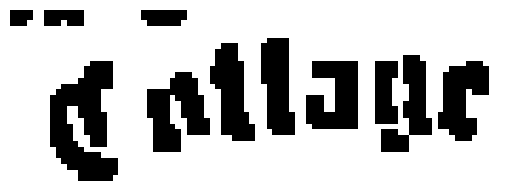

In [15]:
import cv2
import numpy as np

def preprocess_image2(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Use Gaussian Blur for initial noise reduction
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Enhance contrast using CLAHE
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    contrast_enhanced = clahe.apply(blurred)

    # Perform Otsu's thresholding for binarization
    _, binarized = cv2.threshold(
        contrast_enhanced, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Apply morphological closing to remove small noise
    kernel = np.ones((3, 3), np.uint8)
    cleaned = cv2.morphologyEx(binarized, cv2.MORPH_CLOSE, kernel)

    return cleaned

# Example usage
image = cv2.imread(train_images[600])
processed_image = preprocess_image2(image)
import matplotlib.pyplot as plt

# Displaying the image using matplotlib
plt.imshow(processed_image, cmap='gray')
#plt.imshow(image)
plt.axis('off') 
plt.show()


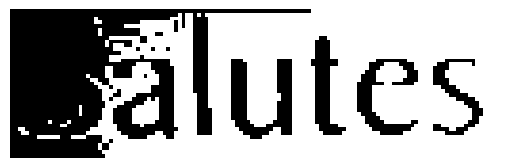

In [16]:
def threshold(img):
    gray=cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img=cv2.threshold(gray,100,255,cv2.THRESH_OTSU + cv2.THRESH_BINARY)[1]
    return img
image = cv2.imread(train_images[2])
im=threshold(image)
plt.imshow(im, cmap='gray')

plt.axis('off') 
plt.show()

In [17]:
train_labels[601]

'of'

In [43]:
char_list=sorted(test_characters)

In [44]:
from tensorflow.keras.layers import Attention

In [101]:
inputs = Input(shape=(32,128,1))

conv_1 = Conv2D(64, (3,3), activation = 'relu', padding='same')(inputs)

pool_1 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_1)
 
conv_2 = Conv2D(128, (3,3), activation = 'relu', padding='same')(pool_1)
pool_2 = MaxPool2D(pool_size=(2, 2), strides=2)(conv_2)
 
conv_3 = Conv2D(256, (3,3), activation = 'relu', padding='same')(pool_2)

conv_4 = Conv2D(256, (3,3), activation = 'relu', padding='same')(conv_3)
conv_4 = Dropout(0.2)(conv_4)

pool_4 = MaxPool2D(pool_size=(2, 1))(conv_4)
 
conv_5 = Conv2D(512, (3,3), activation = 'relu', padding='same')(pool_4)

batch_norm_5 = BatchNormalization()(conv_5)
 
conv_6 = Conv2D(512, (3,3), activation = 'relu', padding='same')(batch_norm_5)
batch_norm_6 = BatchNormalization()(conv_6)
pool_6 = MaxPool2D(pool_size=(2, 1))(batch_norm_6)
 
conv_7 = Conv2D(512, (2,2), activation = 'relu')(pool_6)
 
squeezed = Lambda(lambda x: K.squeeze(x, 1))(conv_7)
 
blstm_1 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(squeezed)
blstm_2 = Bidirectional(LSTM(128, return_sequences=True, dropout = 0.2))(blstm_1)
attention = Attention()([blstm_2, blstm_2])
blstm_attention = Bidirectional(LSTM(128, return_sequences=True, dropout=0.2))(attention)

outputs = Dense(len(char_list)+1, activation = 'softmax')(blstm_2)

act_model = Model(inputs, outputs)

In [102]:
act_model.summary()

Model: "model_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 32, 128, 1)]      0         
                                                                 
 conv2d_32 (Conv2D)          (None, 32, 128, 64)       640       
                                                                 
 max_pooling2d_18 (MaxPoolin  (None, 16, 64, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_33 (Conv2D)          (None, 16, 64, 128)       73856     
                                                                 
 max_pooling2d_19 (MaxPoolin  (None, 8, 32, 128)       0         
 g2D)                                                            
                                                                 
 conv2d_34 (Conv2D)          (None, 8, 32, 256)        2951

In [103]:
paths=train_images+test_images
labels=train_labels+test_labels

In [23]:
!pip install albumentations

  Using cached albumentations-1.4.23-py3-none-any.whl.metadata (36 kB)
  Using cached pydantic-2.10.4-py3-none-any.whl.metadata (29 kB)
  Using cached albucore-0.0.21-py3-none-any.whl.metadata (5.3 kB)
  Using cached eval_type_backport-0.2.2-py3-none-any.whl.metadata (2.2 kB)
  Using cached stringzilla-3.11.2-cp310-cp310-manylinux_2_5_x86_64.manylinux1_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached simsimd-6.2.1-cp310-cp310-manylinux_2_28_x86_64.whl.metadata (66 kB)
  Using cached annotated_types-0.7.0-py3-none-any.whl.metadata (15 kB)
  Using cached pydantic_core-2.27.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (6.6 kB)
Using cached albumentations-1.4.23-py3-none-any.whl (269 kB)
Using cached albucore-0.0.21-py3-none-any.whl (12 kB)
Using cached pydantic-2.10.4-py3-none-any.whl (431 kB)
Using cached pydantic_core-2.27.2-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (2.0 MB)
Using cached eval_type_backport-0.2.2-py3-none-any.whl 

In [69]:
import albumentations as A

In [104]:
import cv2
import numpy as np

def preprocess_images(paths, labels):
    training_img = []
    training_txt = []
    train_input_length = []
    train_label_length = []
    valid_img = []
    valid_txt = []
    valid_input_length = []
    valid_label_length = []

    max_label_len = 0

    for i, (path, label) in enumerate(zip(paths, labels)):
       
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2GRAY)
        #img=cv2.threshold(img,100,255,cv2.THRESH_OTSU + cv2.THRESH_BINARY)[1]
        h, w = img.shape
        if h > 32 or w > 128:
            img = cv2.resize(img, (128, 32))
            h, w = img.shape 

        
        if h < 32:
            add_zeros = np.ones((32 - h, w)) * 255
            img = np.concatenate((img, add_zeros), axis=0)
            h, w = img.shape  
            

        
        if w < 128:
            add_zeros = np.ones((h, 128 - w)) * 255
            img = np.concatenate((img, add_zeros), axis=1)
            h, w = img.shape  
            

        img = np.expand_dims(img, axis=2) / 255.0

        
        if len(label) > max_label_len:
            max_label_len = len(label)

       
        if i % 10 == 0:
            
            valid_img.append(img)
            valid_txt.append(label)
            valid_input_length.append(31)  
            valid_label_length.append(len(label))
        else:
            transform = A.Compose([
                        A.Rotate(limit=5, p=1.0),  
                        A.RandomCrop(height=32, width=128, p=1.0),  
                        A.ColorJitter(p=0.5),  
                        A.GaussianBlur(p=0.2)
                                      ])

            augmented_image = transform(image=img)['image']           

            
            training_img.append(augmented_image )
            training_txt.append(label)
            train_input_length.append(31) 
            train_label_length.append(len(label))

 
    return {
        'training_img': training_img,
        'training_txt': training_txt,
        'train_input_length': train_input_length,
        'train_label_length': train_label_length,
        'valid_img': valid_img,
        'valid_txt': valid_txt,
        'valid_input_length': valid_input_length,
        'valid_label_length': valid_label_length,
        'max_label_len': max_label_len
    }



In [105]:
preprocessed_data = preprocess_images(paths, labels)
training_img = preprocessed_data['training_img']
training_txt = preprocessed_data['training_txt']
train_input_length = preprocessed_data['train_input_length']
train_label_length = preprocessed_data['train_label_length']

valid_img = preprocessed_data['valid_img']
valid_txt = preprocessed_data['valid_txt']
valid_input_length = preprocessed_data['valid_input_length']
valid_label_length = preprocessed_data['valid_label_length']

max_label_len = preprocessed_data['max_label_len']
print("Training Images:", len(training_img))
print("Validation Images:", len(valid_img))
print("Max Label Length:", max_label_len)


Training Images: 4500
Validation Images: 500
Max Label Length: 22


In [106]:
max_label_len=preprocessed_data['max_label_len']

In [107]:
def text_to_sequence(text, char_to_index):
    return [char_to_index[char] for char in text if char in char_to_index]


In [108]:
char_to_index = {char: idx for idx, char in enumerate(char_list)}

In [109]:
training_seq = [text_to_sequence(label, char_to_index) for label in training_txt]
train_padded_txt = pad_sequences(training_seq, maxlen=max_label_len, padding='post', value=len(char_list))
valid_seq = [text_to_sequence(label, char_to_index) for label in valid_txt]
valid_padded_txt = pad_sequences(valid_seq, maxlen=max_label_len, padding='post', value=len(char_list))
train_img = np.array(training_img)
train_input_length = np.array(train_input_length)
train_label_length = np.array(train_label_length)
valid_img = np.array(valid_img)
valid_input_length = np.array(valid_input_length)
valid_label_length = np.array(valid_label_length)

In [110]:
train_img.shape

(4500, 32, 128, 1)

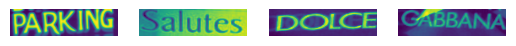

In [111]:
import matplotlib.pyplot as plt

num_images_to_display = 4

for i in range(num_images_to_display):
    plt.subplot(1, num_images_to_display, i+1)
    plt.imshow(train_img[i])  
    plt.axis('off') 
plt.show()

In [112]:
training_txt[:4]

['parking', 'salutes', 'dolce', 'gabbana']

In [34]:
!pip install tensorflow-addons==0.17.1


  Using cached tensorflow_addons-0.17.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.8 kB)
Using cached tensorflow_addons-0.17.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (1.1 MB)


In [96]:
import tensorflow_addons as tfa
from tensorflow.keras.optimizers import Adam

In [113]:
labels = Input(name='the_labels', shape=[max_label_len], dtype='float32')
input_length = Input(name='input_length', shape=[1], dtype='int64')
label_length = Input(name='label_length', shape=[1], dtype='int64')
 
optimizer = tfa.optimizers.RectifiedAdam(learning_rate=0.001)

def ctc_lambda_func(args):
    y_pred, labels, input_length, label_length = args
 
    return K.ctc_batch_cost(labels, y_pred, input_length, label_length)

 
loss_out = Lambda(ctc_lambda_func, output_shape=(1,), name='ctc')([outputs, labels, input_length, label_length])

model = Model(inputs=[inputs, labels, input_length, label_length], outputs=loss_out)
model.compile(loss={'ctc': lambda y_true, y_pred: y_pred}, optimizer = optimizer)
 
filepath="iii5k_model2.hdf5"
checkpoint = ModelCheckpoint(filepath=filepath, monitor='val_loss', verbose=1, save_best_only=True, mode='auto')
callbacks_list = [checkpoint]

In [114]:
batch_size = 32
epochs = 60

history=model.fit(x=[train_img, train_padded_txt, train_input_length, train_label_length], y=np.zeros(len(train_img)), batch_size=batch_size, epochs = epochs, validation_data = ([valid_img, valid_padded_txt, valid_input_length, valid_label_length], [np.zeros(len(valid_img))]), verbose = 1, callbacks = callbacks_list)

Epoch 1/60
140/141 [============================>.] - ETA: 0s - loss: 19.3125
Epoch 1: val_loss improved from inf to 83.68078, saving model to iii5k_model2.hdf5
141/141 [==============================] - 19s 76ms/step - loss: 19.3077 - val_loss: 83.6808
Epoch 2/60
140/141 [============================>.] - ETA: 0s - loss: 17.2649
Epoch 2: val_loss improved from 83.68078 to 34.82836, saving model to iii5k_model2.hdf5
141/141 [==============================] - 9s 62ms/step - loss: 17.2620 - val_loss: 34.8284
Epoch 3/60
140/141 [============================>.] - ETA: 0s - loss: 16.8654
Epoch 3: val_loss improved from 34.82836 to 17.31275, saving model to iii5k_model2.hdf5
141/141 [==============================] - 9s 62ms/step - loss: 16.8703 - val_loss: 17.3128
Epoch 4/60
140/141 [============================>.] - ETA: 0s - loss: 16.5807
Epoch 4: val_loss improved from 17.31275 to 16.27697, saving model to iii5k_model2.hdf5
141/141 [==============================] - 9s 62ms/step - loss: 

In [115]:
act_model.load_weights('iii5k_model2.hdf5')
 
prediction = act_model.predict(valid_img[:10])
 
out = K.get_value(K.ctc_decode(prediction, input_length=np.ones(prediction.shape[0])*prediction.shape[1],
                         greedy=True)[0][0])
 
i = 0
for x in out:
    print("original_text =  ", valid_txt[i])
    print("predicted text = ", end = '')
    for p in x:  
        if int(p) != -1:
            print(char_list[int(p)], end = '')       
    print('\n')
    i+=1

1/1 [==============================] - 10s 10s/step
original_text =   private
predicted text = private

original_text =   kingfisher
predicted text = finggsher

original_text =   loans
predicted text = loans

original_text =   bank
predicted text = bants

original_text =   gypsy
predicted text = sypsy

original_text =   regency
predicted text = regency

original_text =   state
predicted text = sate

original_text =   bank
predicted text = bank

original_text =   by
predicted text = by

original_text =   550
predicted text = 550



In [116]:
import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer

def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

predictions = act_model.predict(valid_img)
decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])

decoded_predictions = [''.join([char_list[int(p)] for p in x if int(p) != -1]) for x in decoded_output]

cer = calculate_cer(decoded_predictions, valid_txt)
print(f"CER: {cer * 100:.2f}%")

wer = calculate_wer(decoded_predictions, valid_txt)
print(f"WER: {wer * 100:.2f}%")


16/16 [==============================] - 0s 15ms/step
CER: 19.37%
WER: 44.00%


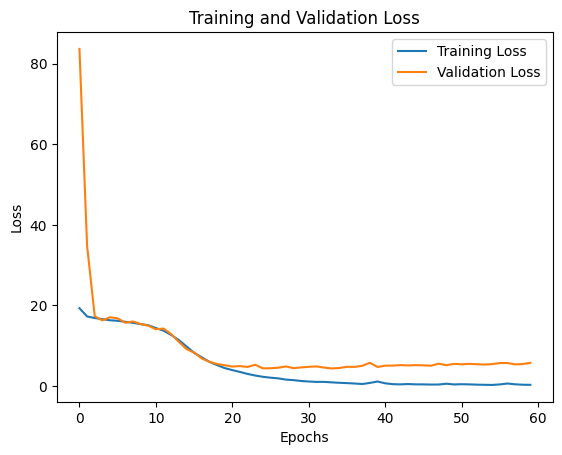

In [117]:
history_dict = history.history

plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

In [65]:
import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer

def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

predictions = act_model.predict(valid_img)
decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])

decoded_predictions = [''.join([char_list[int(p)] for p in x if int(p) != -1]) for x in decoded_output]

cer = calculate_cer(decoded_predictions, valid_txt)
print(f"CER: {cer * 100:.2f}%")

wer = calculate_wer(decoded_predictions, valid_txt)
print(f"WER: {wer * 100:.2f}%")


16/16 [==============================] - 0s 15ms/step
CER: 26.15%
WER: 57.80%


In [40]:
act_model.load_weights('iii5k_model.hdf5')
 
prediction = act_model.predict(valid_img[:10])
 
out = K.get_value(K.ctc_decode(prediction, input_length=np.ones(prediction.shape[0])*prediction.shape[1],
                         greedy=True)[0][0])
 
i = 0
for x in out:
    print("original_text =  ", valid_txt[i])
    print("predicted text = ", end = '')
    for p in x:  
        if int(p) != -1:
            print(char_list[int(p)], end = '')       
    print('\n')
    i+=1

1/1 [==============================] - 0s 32ms/step
original_text =   private
predicted text = private

original_text =   kingfisher
predicted text = rngesher

original_text =   loans
predicted text = loans

original_text =   bank
predicted text = bank

original_text =   gypsy
predicted text = ghypsy

original_text =   regency
predicted text = regency

original_text =   state
predicted text = shate

original_text =   bank
predicted text = bank

original_text =   by
predicted text = by

original_text =   550
predicted text = 350



In [41]:
!pip install editdistance

  Using cached editdistance-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (3.9 kB)
Using cached editdistance-0.8.1-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (401 kB)


In [42]:
import editdistance

def calculate_cer(predictions, ground_truths):
    cer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]  
        cer_total += editdistance.eval(pred, gt_text)  
    cer = cer_total / sum(len(gt) for gt in ground_truths)  
    return cer

def calculate_wer(predictions, ground_truths):
    wer_total = 0
    for i, pred in enumerate(predictions):
        gt_text = ground_truths[i]
        pred_words = pred.split() 
        gt_words = gt_text.split()  
        wer_total += editdistance.eval(pred_words, gt_words)  
    wer = wer_total / sum(len(gt.split()) for gt in ground_truths)  
    return wer

predictions = act_model.predict(valid_img)
decoded_output = K.get_value(K.ctc_decode(predictions, input_length=np.ones(predictions.shape[0]) * predictions.shape[1], greedy=True)[0][0])

# Decode predictions
decoded_predictions = [''.join([char_list[int(p)] for p in x if int(p) != -1]) for x in decoded_output]

# Calculate CER
cer = calculate_cer(decoded_predictions, valid_txt)
print(f"CER: {cer * 100:.2f}%")

# Calculate WER
wer = calculate_wer(decoded_predictions, valid_txt)
print(f"WER: {wer * 100:.2f}%")


16/16 [==============================] - 0s 16ms/step
CER: 23.83%
WER: 54.00%
